### Elbow method

The optimal number of clusters based on the elbow method is: 10


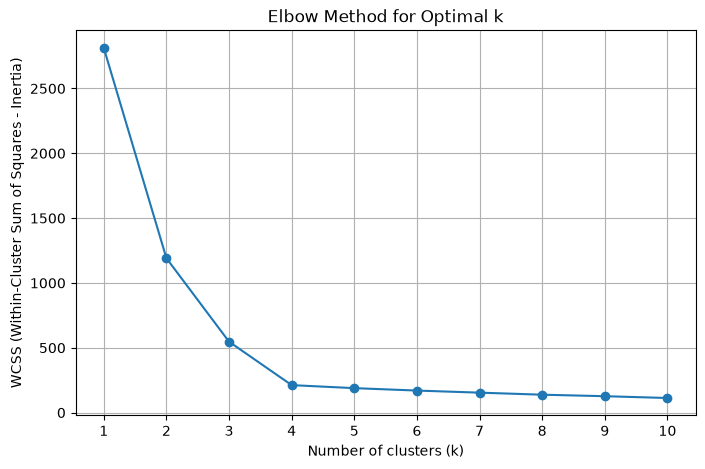

In [3]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs


X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=0)

wcss = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++',  n_init=10, random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_) # inertia is the sum of squared distances of samples to their closest cluster center


best_k = k_range[wcss.index(min(wcss))]  # Find the k with the minimum WCSS
print(f"The optimal number of clusters based on the elbow method is: {best_k}")

# Plotting the elbow method graph
plt.figure(figsize=(8, 5))
plt.plot(k_range, wcss, marker='o')
plt.title('Elbow Method for Optimal k')
plt.xlabel('Number of clusters (k)')
plt.ylabel('WCSS (Within-Cluster Sum of Squares - Inertia)')
plt.xticks(k_range)
plt.grid()
plt.show()

### Silhouette metod

The optimal number of clusters based on silhouette score is: 4 with a score of 0.6820


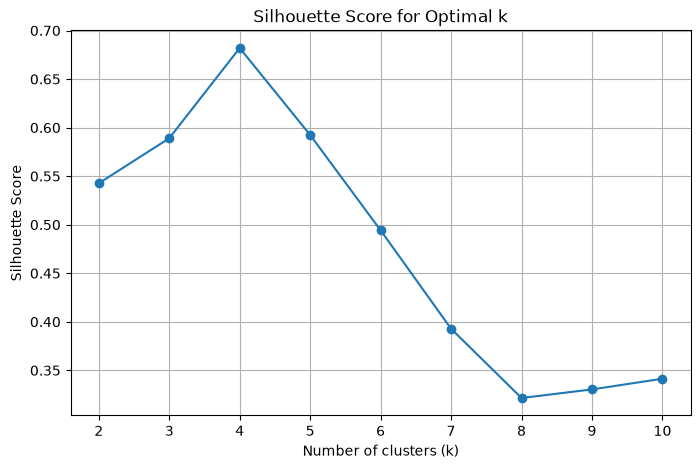

In [2]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):  # Silhouette score is not defined for k=1
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = kmeans.fit_predict(X)
    score = silhouette_score(X, labels=labels)
    silhouette_scores.append(score)


best_k = range(2, 11)[silhouette_scores.index(max(silhouette_scores))]
print(f"The optimal number of clusters based on silhouette score is: {best_k} with a score of {max(silhouette_scores):.4f}")

# Search for the optimal number of clusters based on silhouette score
plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.title('Silhouette Score for Optimal k')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 11))
plt.grid()
plt.show()
